# DataVerse 001 · Belo Horizonte's housing market in ITBI records

Belo Horizonte publishes records of property transactions reported for the municipal transfer tax, the ITBI (*Imposto sobre a Transmissão de Bens Imóveis*). The `pracadata/brazil-itbi` dataset on Hugging Face harmonises those records into one table spanning January 2008 to September 2026. The [project notes](README.md) describe the pinned input, attribution and publication checks.

The notebook asks four questions about houses and apartments sold between 2016 and 2025:

1. Where in the city is a square metre most expensive?
2. How does price change with distance from the city centre?
3. How did real declared values and ITBI tax bases change after adjusting for property characteristics?
4. Do declared prices cluster on round numbers, and by how much?

Two limits apply throughout. Each record carries a **declared** value and a **tax base**. These are administrative measures, and the choice between them changes the answer to question 3. And the analysis is exploratory: filters and model specifications were chosen after looking at the data, so the intervals describe sampling uncertainty given those choices, not the uncertainty of the whole analytical path.

Code and prose are in English. Every figure is drawn twice, in Brazilian Portuguese and in English, and both versions are saved.

## 1. Setup

Install this project environment with `uv sync --project projects/001-bh-itbi` from the repository root, and select its `.venv/bin/python` as the notebook kernel. The local `dataverse-style` dependency provides `dataverse_style` without path manipulation.

The first data run downloads the pinned Hugging Face dataset and base-map tiles, which are cached. Font registration is local and optional: install IBM Plex explicitly with `ensure_fonts("fonts", download=True)` if desired; otherwise built-in DejaVu fallbacks are used. Shared settings follow the imports. The round-number settings and figure text stay with their respective analyses.

In [1]:
from pathlib import Path

import contextily as ctx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from huggingface_hub import hf_hub_download
from IPython.display import display
from matplotlib import patheffects
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap, to_rgb
from matplotlib.ticker import FuncFormatter

from dataverse_style import (
    DEFAULT_THEME,
    editorial_figure,
    editorial_subplots,
    format_brl,
    number_formatter,
    plot_band,
    plot_line,
    register_fonts,
    save_figure,
    style_axes,
    use,
)

In [2]:
# --- Data ------------------------------------------------------------------
REPO_ID = "pracadata/brazil-itbi"
FILENAME = "data/belo_horizonte_transactions.parquet"
# Pinned dataset commit, so the notebook keeps reading the same file
# even if the dataset is updated later.
REVISION = "5908d77ed56fc9adb6dbafaf2cb38f34245bcd76"
START_YEAR, END_YEAR = 2016, 2025

# --- Output ----------------------------------------------------------------
LANGUAGES = ("pt", "en")
OUTPUT_DIR = Path("figures")
FONT_DIR = Path("fonts")
TILE_CACHE = Path("tile_cache")

# --- Footer texts ----------------------------------------------------------
SIGNATURE = "Dataverse"
SOURCE = {
    "pt": "Prefeitura de Belo Horizonte (ITBI), via pracadata/brazil-itbi.",
    "en": "Belo Horizonte City Hall (ITBI), via pracadata/brazil-itbi.",
}

# --- Section 4.1: price map --------------------------------------------------
PRACA_SETE = (-19.9191, -43.9386)  # (lat, lon)
MAP_YEAR = 2023
WEB_MERCATOR_RADIUS = 6_378_137.0
BASEMAP = ctx.providers.Esri.WorldTopoMap
BASEMAP_ZOOM = 12
TILE_SATURATION = 0.5  # 1 keeps the tiles' colours, 0 is greyscale
TILE_STRENGTH = 0.6  # 1 keeps the tiles as they are, 0 is plain paper
SHOW_LANDMARKS = True  # switch off if they duplicate the base map's own labels
LANDMARKS = ["SAVASSI", "LOURDES", "BELVEDERE", "BURITIS", "CASTELO", "PAMPULHA"]
POINTS_PER_SALE = 5  # circle area per sale, in points²
SIZE_KEY_COUNTS = [1, 10, 50]
MAP_BOX = [0.05, 0.20, 0.90, 0.62]  # left, bottom, width, height as figure fractions

# --- Section 4.2: distance gradient ------------------------------------------
EARTH_RADIUS_KM = 6_371.0
MAX_DISTANCE_KM = 14
MIN_SALES_PER_BAND = 50
GRADIENT_YEARS = (2022, 2025)

# --- Section 5: hedonic model -------------------------------------------------
MIN_SALES_PER_NEIGHBOURHOOD = 100
MEASURES = {"Declared value": "declared_m2_real", "Tax base": "tax_base_m2_real"}
FORMULA = (
    "np.log({value}) ~ np.log(built_area_m2)"
    " + C(building_age_band, Treatment('26_plus')) + C(property_type)"
    " + C(neighbourhood) + C(year)"
)

# Folders for the saved figures and for what is downloaded once and reused.
for folder in (OUTPUT_DIR, FONT_DIR, TILE_CACHE):
    folder.mkdir(exist_ok=True)
ctx.set_cache_dir(str(TILE_CACHE))

### House style

Every figure is built on the same base, meant to be reused in later DataVerse posts:

- **Header:** a short accent bar, a serif title that states the finding in one line, and a one-sentence subtitle saying what is measured, where and when.
- **Plot:** the unit is written once above the axis, gridlines are thin, series and places are labelled directly on the data, and one accent colour marks what carries the argument.
- **Footer:** a thin rule, then the source and the methodological note on separate lines, with the repository on the right.
- **Baseline:** the bottom axis line is drawn dark only when the axis starts at zero, so it never suggests a zero that is not there.

Margins and text sizes are set in points. `editorial_subplots` reserves space for the header and footer around its subplot grid. The map uses `editorial_figure` with manually placed Matplotlib axes. `save_figure` finalises the composition before export.

In [3]:
# Register the existing optional typefaces; missing files use built-in fallbacks.
register_fonts(FONT_DIR)
use()

Theme(paper='#fbfaf7', ink='#1f1f1f', subtle='#4a4a48', muted='#6b6b6b', rule='#dcd8cf', axis='#8f8b83', context='#b4b0a8', accent='#0f766e', palette=('#0f766e', '#b45309', '#3b5ba5', '#9b3d6b', '#5b6b2f'), title_font='IBM Plex Serif', text_font='IBM Plex Sans', fallback_serif=('DejaVu Serif', 'serif'), fallback_sans=('DejaVu Sans', 'sans-serif'), title_size=20.0, title_weight='semibold', title_linespacing=1.15, subtitle_size=11.0, subtitle_linespacing=1.4, note_size=7.5, note_linespacing=1.45, signature_weight='semibold', unit_size=9.0, tick_size=9.0, label_size=9.5, annotation_size=9.0, margin_pt=26.0, accent_bar_width_pt=34.0, accent_bar_height_pt=3.0, accent_bar_gap_pt=12.0, title_gap_pt=7.0, header_gap_pt=18.0, footer_gap_pt=18.0, footer_bottom_offset_pt=4.0, footer_rule_gap_pt=7.0, footer_rule_width=0.8, footer_text_width_fraction=0.72, footer_signature_gap_pt=12.0, spine_width=0.8, zero_spine_width=1.0, grid_width=0.6, tick_length=3.5, tick_width=0.8, xtick_pad=4.0, ytick_pad=6.

## 2. Data

The values arrive as Python `Decimal` objects, which keep the exact cents of the source but make arithmetic slow and break some pandas operations. They are converted to floats once, here, so no later cell needs to convert them again.

In [4]:
# Download the file once (later runs read the local Hugging Face cache) and load it.
parquet_path = hf_hub_download(
    repo_id=REPO_ID, repo_type="dataset", filename=FILENAME, revision=REVISION
)
transactions = pd.read_parquet(parquet_path)

# Decimal to float, dates to datetime, neighbourhood names to one spelling.

NUMERIC_COLUMNS = [
    "value_declared_brl",
    "value_tax_base_brl",
    "value_declared_brl_real",
    "built_area_m2",
    "price_per_m2_brl",
    "price_per_m2_brl_real",
]
transactions[NUMERIC_COLUMNS] = transactions[NUMERIC_COLUMNS].astype(float)
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"])
transactions["neighbourhood"] = transactions["neighbourhood"].str.strip().str.upper()

print(
    f"{len(transactions):,} transactions, "
    f"{transactions['transaction_date'].min():%b %Y} to "
    f"{transactions['transaction_date'].max():%b %Y}"
)

# Missingness of fields used for filtering, measurement or geocoding.
inspection_columns = [
    "value_declared_brl",
    "value_tax_base_brl",
    "built_area_m2",
    "building_age_band",
    "geo_precision",
]
missing = transactions[inspection_columns].isna().sum().to_frame("Missing records")
display(missing.style.format("{:,}"))

516,725 transactions, Jan 2008 to Sep 2026


,Missing records
value_declared_brl,0
value_tax_base_brl,0
built_area_m2,"22,565"
building_age_band,"22,553"
geo_precision,0


### Which transactions are analysed

Five rules define the analysed set, applied in this order:

1. **Houses and apartments only.** Shops, offices, land and parking spaces follow different price logics.
2. **No value flag.** The source flags two kinds of unusable value: symbolic values (a nominal amount, typical of transfers between relatives) and guides that cover several units with one value, which makes the price of any single unit unknowable.
3. **A positive built area**, needed for the price per m².
4. **A declared price per m² between R$ 100 and R$ 200,000**, which trims extreme recorded values. The bounds may also exclude genuine transactions.
5. **Sold between 2016 and 2025**, a recent ten-year window in which every year is complete.

The location precision is not a rule here: only the two spatial figures in section 4 need street-level coordinates, and they apply that filter themselves.

In [5]:
# Each rule is a boolean mask over all transactions, in the order it is applied.
rules = {
    "House or apartment": transactions["property_type"].isin(["apartment", "house"]),
    "No value flag": transactions["value_flag"].isna(),
    "Positive built area": transactions["built_area_m2"] > 0,
    "Price per m² in [R$ 100, R$ 200,000]": transactions["price_per_m2_brl"].between(100, 200_000),
    f"Sold {START_YEAR}–{END_YEAR}": transactions["year"].between(START_YEAR, END_YEAR),
}

# Apply the rules one after another, recording how many rows each one removes.
kept = pd.Series(True, index=transactions.index)
funnel_rows = [{"rule": "All transactions", "kept": len(transactions), "removed": 0}]
for rule, mask in rules.items():
    removed = (kept & ~mask).sum()
    kept &= mask
    funnel_rows.append({"rule": rule, "kept": kept.sum(), "removed": removed})

# The analysed set, used by every later section.
residential = transactions.loc[kept].copy()
display(pd.DataFrame(funnel_rows).set_index("rule").style.format("{:,}"))

,kept,removed
rule,,
All transactions,"516,725",0
House or apartment,"410,657","106,068"
No value flag,"400,444","10,213"
Positive built area,"400,412",32
"Price per m² in [R$ 100, R$ 200,000]","398,678","1,734"
Sold 2016–2025,"205,436","193,242"


## 3. Audit

Two checks come before any figure that will be published.

### 3.1 Records per year

The source is not uniform over time. 2014 has far fewer records than its neighbours, for a reason the dataset does not document, and 2026 stops at the end of September. Neither year is in the analysed period, but both would distort any figure that spans the full series.

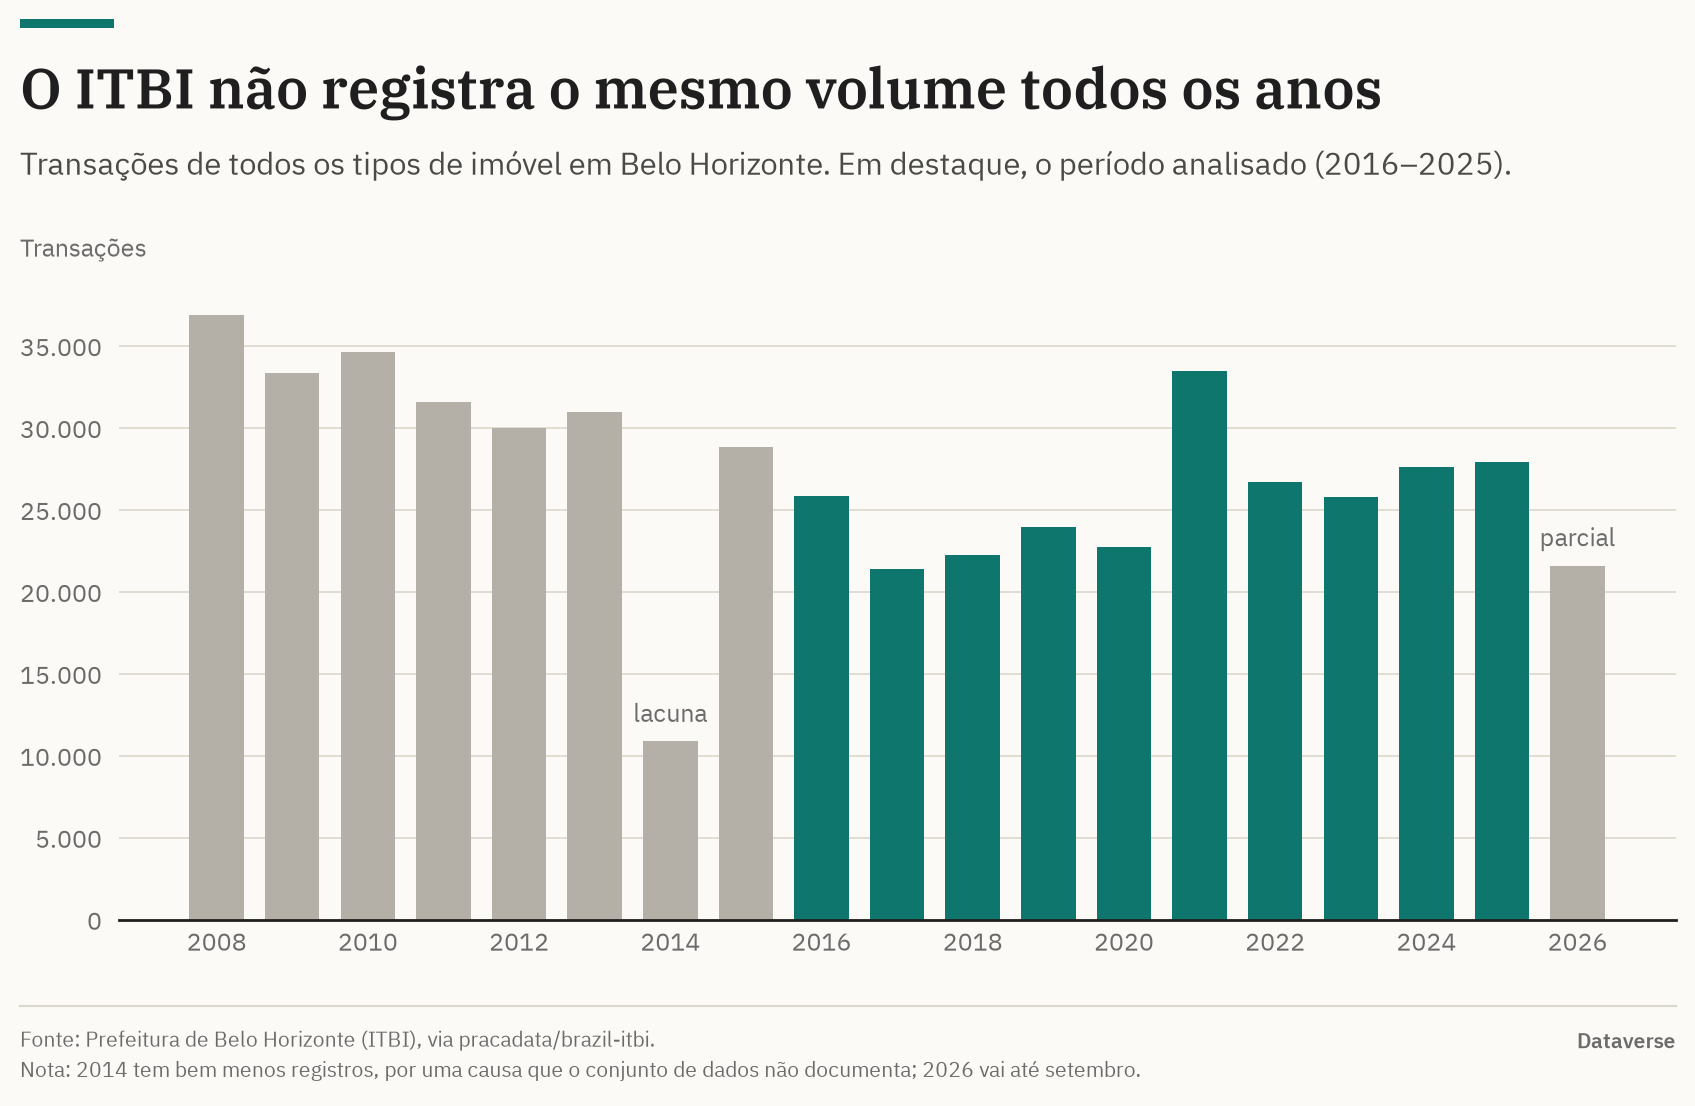

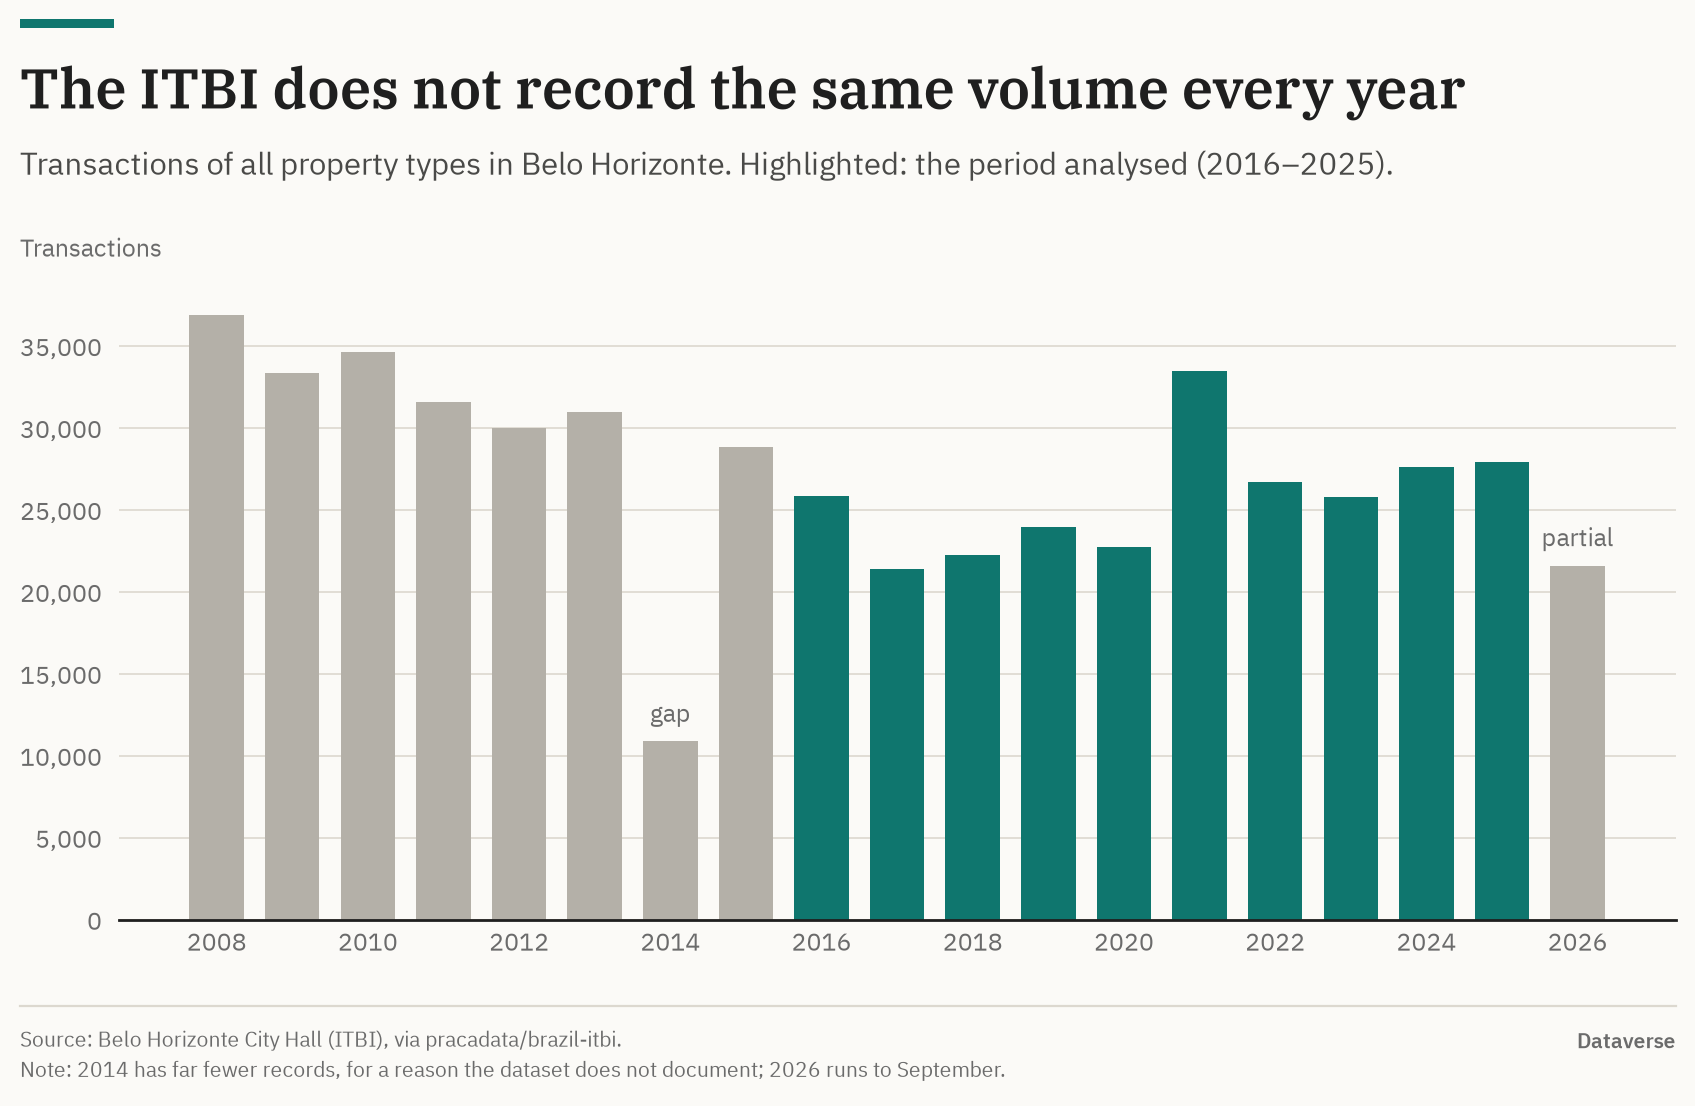

In [6]:
# Number of records in each year, and which years belong to the analysed period.
records_per_year = transactions["year"].value_counts().sort_index()
in_window = records_per_year.index.to_series().between(START_YEAR, END_YEAR)

YEAR_TEXT = {
    "pt": {
        "title": "O ITBI não registra o mesmo volume todos os anos",
        "subtitle": (
            f"Transações de todos os tipos de imóvel em Belo Horizonte. "
            f"Em destaque, o período analisado ({START_YEAR}–{END_YEAR})."
        ),
        "unit": "Transações",
        "gap": "lacuna",
        "partial": "parcial",
        "note": (
            "2014 tem bem menos registros, por uma causa que o conjunto de dados "
            "não documenta; 2026 vai até setembro."
        ),
    },
    "en": {
        "title": "The ITBI does not record the same volume every year",
        "subtitle": (
            f"Transactions of all property types in Belo Horizonte. "
            f"Highlighted: the period analysed ({START_YEAR}–{END_YEAR})."
        ),
        "unit": "Transactions",
        "gap": "gap",
        "partial": "partial",
        "note": (
            "2014 has far fewer records, for a reason the dataset does not "
            "document; 2026 runs to September."
        ),
    },
}

for lang in LANGUAGES:
    text = YEAR_TEXT[lang]
    fig, ax = editorial_subplots(
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE,
        note=text["note"],
        signature=SIGNATURE,
        lang=lang,
        theme="landscape",
    )

    # Bars: accent inside the analysed period, grey outside it.
    ax.bar(
        records_per_year.index,
        records_per_year.to_numpy(),
        width=0.72,
        color=np.where(in_window, DEFAULT_THEME.accent, DEFAULT_THEME.context),
    )

    # The two years that need a word of explanation.
    for label_year, label in [(2014, text["gap"]), (2026, text["partial"])]:
        ax.annotate(
            label,
            (label_year, records_per_year[label_year]),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color=DEFAULT_THEME.muted,
        )

    # Bars start at zero, so the baseline is drawn dark.
    style_axes(ax, text["unit"], zero_baseline=True)
    ax.tick_params(axis="x", length=0)
    ax.set_xticks(records_per_year.index[::2])
    ax.yaxis.set_major_formatter(number_formatter(lang))

    save_figure(fig, OUTPUT_DIR / f"00_records_per_year_{lang}.png", show=True)

### 3.2 Declared value against the tax base

Each record has two values: the value the parties declared and the tax base (*base de cálculo*) used to calculate ITBI. With a tolerance of R$1, no transaction in the analysed set has a declared value above its tax base. Over the whole period about half declare the base and half declare less. The share declaring less falls from around 70% in 2016–2018 to around 25% in 2023–2024.

Belo Horizonte's [published legislation](https://fazenda.pbh.gov.br/legislacao/formkey.asp?key=17) describes a municipal assessment or the declared value when higher. The [Superior Court of Justice's Tema 1.113](https://processo.stj.jus.br/repetitivos/temas_repetitivos/pesquisa.jsp?cod_tema_final=1113&cod_tema_inicial=1113&novaConsulta=true&tipo_pesquisa=T) presumes the declared value reflects market value and limits when the tax authority can set it aside. How those rules were applied to these records across 2016–2025 remains open. The observed gap between the two recorded values changes over time, which matters for the comparison in section 5.

In [7]:
# Classify each sale by how its declared value compares with its tax base.
# A tolerance of R$ 1 absorbs rounding differences between the two values.
gap = residential["value_declared_brl"] - residential["value_tax_base_brl"]
relation = pd.cut(
    gap,
    [-np.inf, -1, 1, np.inf],
    labels=["declared below base", "declared equals base", "declared above base"],
).rename("relation")

# Share of each class per year, plus one row for the whole period.
# dropna=False keeps the "above base" column even though it is empty.
base_check = pd.crosstab(residential["year"], relation, normalize="index", dropna=False)
base_check.loc[f"{START_YEAR}–{END_YEAR}"] = relation.value_counts(normalize=True)
display(base_check.style.format("{:.1%}"))

relation,declared below base,declared equals base,declared above base
year,,,
2016,69.0%,31.0%,0.0%
2017,72.6%,27.4%,0.0%
2018,69.6%,30.4%,0.0%
2019,66.4%,33.6%,0.0%
2020,54.6%,45.4%,0.0%
2021,45.7%,54.3%,0.0%
2022,35.4%,64.6%,0.0%
2023,27.3%,72.7%,0.0%
2024,24.5%,75.5%,0.0%


## 4. Where the money is

Both figures in this section place each sale on the map, so they use only transactions geocoded to the street face (`face_centroid`), the most precise location the source offers. Sales located only by postcode or neighbourhood centroid would pile up on a handful of points and distort both the map and the distances.

### 4.1 The price map

Street-face geocoding gives every sale on the same face the same coordinates: the 13,997 apartment sales of 2023 sit on only 4,920 distinct points. Drawn one dot per sale, about two thirds of them would be hidden under others. The map therefore draws one circle per street face, with its area proportional to the number of sales there and its colour set by their median declared price per m². Size shows where the market is active; colour shows what a square metre costs.

The map uses nominal values for a single year. The five colour classes use quintile cut points computed from individual sales. Each street-face median is assigned to one of those classes, so the numbers of faces and sales represented by each colour can differ. The largest circles are drawn first, so smaller ones remain visible on top of them.

The base map is the Esri World Topo Map, half desaturated and blended towards the paper colour, so relief, roads and water stay as context and the circles carry the colour.

In [8]:
# Apartment sales of the map year that are located to the street face.
map_sales = residential.loc[
    (residential["geo_precision"] == "face_centroid")
    & (residential["property_type"] == "apartment")
    & (residential["year"] == MAP_YEAR)
].copy()

# The base-map tiles are in Web Mercator, so coordinates are projected to match.
map_sales["x"] = WEB_MERCATOR_RADIUS * np.radians(map_sales["lon"])
map_sales["y"] = WEB_MERCATOR_RADIUS * np.log(np.tan(np.pi / 4 + np.radians(map_sales["lat"]) / 2))
centre_x = WEB_MERCATOR_RADIUS * np.radians(PRACA_SETE[1])
centre_y = WEB_MERCATOR_RADIUS * np.log(np.tan(np.pi / 4 + np.radians(PRACA_SETE[0]) / 2))

# One circle per street face: number of sales and their median price per m².
faces = (
    map_sales.groupby(["x", "y"])["price_per_m2_brl"]
    .agg(median="median", sales="size")
    .reset_index()
    .sort_values("sales", ascending=False)  # largest drawn first, small ones on top
)
# Neighbourhood labels sit at the median location of their own sales.
landmark_points = (
    map_sales.groupby("neighbourhood")[["x", "y"]].median().reindex(LANDMARKS).dropna()
)

# Use transaction-level quintile cut points to classify street-face medians.
price_edges = np.quantile(map_sales["price_per_m2_brl"], np.linspace(0, 1, 6))
class_cmap = ListedColormap(plt.cm.plasma_r(np.linspace(0.12, 0.92, 5)))
class_norm = BoundaryNorm(price_edges, class_cmap.N)

# Extent: the data's bounding box, widened to the shape of the map box so the
# base map fills the frame.
box_ratio = (MAP_BOX[3] * DEFAULT_THEME.figsize[1]) / (MAP_BOX[2] * DEFAULT_THEME.figsize[0])
x_mid = (faces["x"].min() + faces["x"].max()) / 2
y_mid = (faces["y"].min() + faces["y"].max()) / 2
half_width = 0.52 * max(
    faces["x"].max() - faces["x"].min(),
    (faces["y"].max() - faces["y"].min()) / box_ratio,
)
half_height = half_width * box_ratio
x_limits = (x_mid - half_width, x_mid + half_width)
y_limits = (y_mid - half_height, y_mid + half_height)

# Base map: fetched once (then read from the tile cache) and softened.
basemap_image, basemap_extent = ctx.bounds2img(
    x_limits[0], y_limits[0], x_limits[1], y_limits[1], zoom=BASEMAP_ZOOM, source=BASEMAP
)
# Desaturate: mix each pixel with its own grey value.
tiles = basemap_image[..., :3].astype(float)
tiles = TILE_SATURATION * tiles + (1 - TILE_SATURATION) * tiles.mean(axis=2, keepdims=True)
# Fade: mix the result with the paper colour.
paper_rgb = 255 * np.array(to_rgb(DEFAULT_THEME.paper))
basemap_soft = (TILE_STRENGTH * tiles + (1 - TILE_STRENGTH) * paper_rgb).astype(np.uint8)

print(f"{len(map_sales):,} apartment sales in {MAP_YEAR} on {len(faces):,} street faces")
print("Quintile edges (R$/m²):", np.round(price_edges, -1))

13,997 apartment sales in 2023 on 4,920 street faces
Quintile edges (R$/m²): [  110.  2900.  3480.  4070.  4990. 17650.]


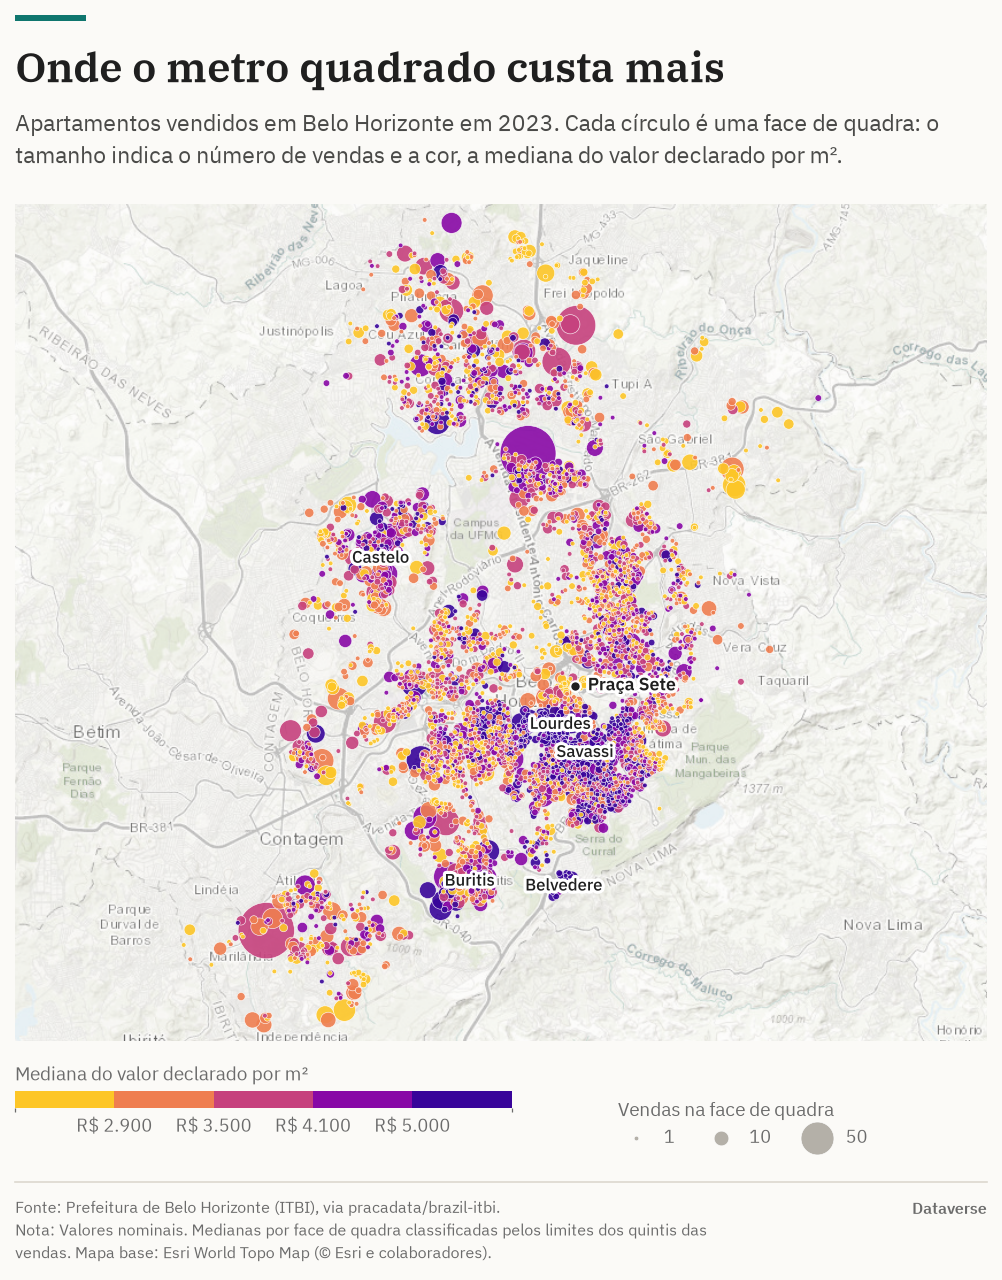

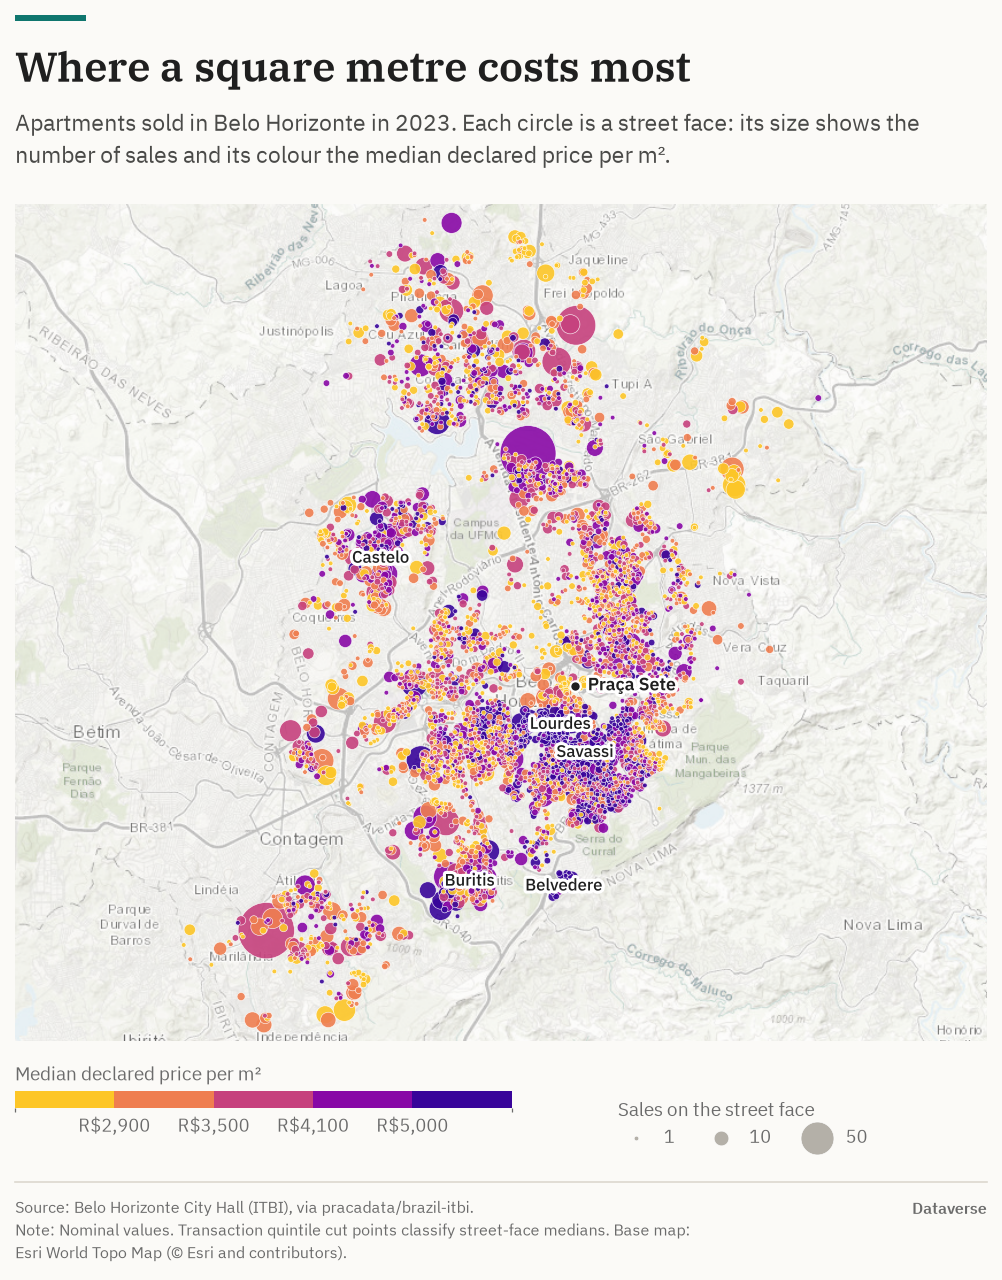

In [9]:
MAP_TEXT = {
    "pt": {
        "title": "Onde o metro quadrado custa mais",
        "subtitle": (
            f"Apartamentos vendidos em Belo Horizonte em {MAP_YEAR}. Cada círculo é uma "
            "face de quadra: o tamanho indica o número de vendas e a cor, a mediana "
            "do valor declarado por m²."
        ),
        "scale": "Mediana do valor declarado por m²",
        "size": "Vendas na face de quadra",
        "note": (
            "Valores nominais. Medianas por face de quadra classificadas pelos limites dos quintis das vendas. "
            "Mapa base: Esri World Topo Map (© Esri e colaboradores)."
        ),
    },
    "en": {
        "title": "Where a square metre costs most",
        "subtitle": (
            f"Apartments sold in Belo Horizonte in {MAP_YEAR}. Each circle is a street "
            "face: its size shows the number of sales and its colour the median "
            "declared price per m²."
        ),
        "scale": "Median declared price per m²",
        "size": "Sales on the street face",
        "note": (
            "Nominal values. Transaction quintile cut points classify street-face medians. "
            "Base map: Esri World Topo Map (© Esri and contributors)."
        ),
    },
}
# White outline behind the labels, so they stay legible over the map.
halo = [patheffects.withStroke(linewidth=3, foreground="white")]

for lang in LANGUAGES:
    text = MAP_TEXT[lang]
    fig = editorial_figure(
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE,
        note=text["note"],
        signature=SIGNATURE,
        lang=lang,
    )
    # The map has a fixed box, because the tiles were fetched for its shape.
    ax = fig.add_axes(MAP_BOX)

    # Base map underneath, circles on top.
    ax.imshow(basemap_soft, extent=basemap_extent, interpolation="bilinear", zorder=0)
    ax.scatter(
        faces["x"],
        faces["y"],
        s=POINTS_PER_SALE * faces["sales"],
        c=faces["median"],
        cmap=class_cmap,
        norm=class_norm,
        alpha=0.9,
        edgecolors="white",
        linewidths=0.3,
        zorder=2,
    )
    # imshow resets the limits to the tiles' extent, so they are set afterwards.
    ax.set_xlim(x_limits)
    ax.set_ylim(y_limits)
    ax.set_aspect("equal")
    ax.axis("off")

    # Labels: Praça Sete with a marker, then the neighbourhood names.
    ax.plot(
        centre_x,
        centre_y,
        marker="o",
        markersize=5,
        color=DEFAULT_THEME.ink,
        markeredgecolor="white",
        zorder=3,
    )
    ax.annotate(
        "Praça Sete",
        (centre_x, centre_y),
        xytext=(6, -2),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="semibold",
        color=DEFAULT_THEME.ink,
        path_effects=halo,
        zorder=3,
    )
    if SHOW_LANDMARKS:
        for name, point in landmark_points.iterrows():
            ax.text(
                point["x"],
                point["y"],
                name.title(),
                fontsize=8,
                fontweight="medium",
                color=DEFAULT_THEME.ink,
                ha="center",
                va="center",
                path_effects=halo,
                zorder=3,
            )

    # Colour key, below the map on the left: only the four inner edges, since
    # the outer two are the extremes of the data and carry no meaning.
    cax = fig.add_axes([MAP_BOX[0], MAP_BOX[1] - 0.05, 0.46, 0.013])
    colourbar = fig.colorbar(
        ScalarMappable(norm=class_norm, cmap=class_cmap),
        cax=cax,
        orientation="horizontal",
        spacing="uniform",
        ticks=price_edges[1:-1],
    )
    colourbar.outline.set_visible(False)
    cax.tick_params(length=0, labelsize=8.5, colors=DEFAULT_THEME.muted)
    cax.set_xticklabels([format_brl(round(edge, -2), lang) for edge in price_edges[1:-1]])
    cax.set_title(text["scale"], fontsize=9, color=DEFAULT_THEME.muted, loc="left", pad=5)

    # Size key, below the map on the right: empty scatters give the legend its circles.
    size_handles = [
        ax.scatter(
            [],
            [],
            s=POINTS_PER_SALE * count,
            color=DEFAULT_THEME.context,
            edgecolors="white",
            linewidths=0.3,
            label=str(count),
        )
        for count in SIZE_KEY_COUNTS
    ]
    size_key = fig.legend(
        handles=size_handles,
        title=text["size"],
        loc="lower left",
        bbox_to_anchor=(0.60, MAP_BOX[1] - 0.085),
        ncol=len(SIZE_KEY_COUNTS),
        frameon=False,
        fontsize=8.5,
        title_fontsize=9,
        labelcolor=DEFAULT_THEME.muted,
        columnspacing=1.6,
        handletextpad=0.6,
        borderpad=0,
        alignment="left",
    )
    size_key.get_title().set_color(DEFAULT_THEME.muted)

    save_figure(fig, OUTPUT_DIR / f"01_price_map_{lang}.png", show=True)

### 4.2 Price and distance from the centre

Each apartment sale of 2022–2025 is placed by its straight-line (haversine) distance from Praça Sete, the conventional centre of Belo Horizonte, and sales are grouped in 1 km bands. The line is each band's median declared price per m², adjusted by IPCA inflation to September 2026 reais; the shaded band runs from the 25th to the 75th percentile, so it holds the middle half of the sales at that distance. Bands with fewer than 50 sales are dropped.

Only one recent period is shown. Comparing periods on declared values would mix price change with changes in how values are declared, a problem section 5 examines. The tables after the next cell list the neighbourhoods behind the first two bands, so the reading of the peak rests on the places actually in it.

In [10]:
# Apartment sales of the chosen period that are located to the street face.
gradient_sales = residential.loc[
    (residential["geo_precision"] == "face_centroid")
    & (residential["property_type"] == "apartment")
    & residential["year"].between(*GRADIENT_YEARS)
].copy()

# Haversine (great-circle) distance from each sale to Praça Sete, in km.
lat, lon = np.radians(gradient_sales["lat"]), np.radians(gradient_sales["lon"])
centre_lat, centre_lon = np.radians(PRACA_SETE)
haversine = (
    np.sin((lat - centre_lat) / 2) ** 2
    + np.cos(lat) * np.cos(centre_lat) * np.sin((lon - centre_lon) / 2) ** 2
)
gradient_sales["distance_km"] = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(haversine))
# Keep the sales within range and assign each to a 1 km band, named by its midpoint.
gradient_sales = gradient_sales.loc[gradient_sales["distance_km"] < MAX_DISTANCE_KM]
gradient_sales["band_km"] = np.floor(gradient_sales["distance_km"]) + 0.5

# Quartiles of the real price per m² in each band, and the number of sales behind them.
gradient = (
    gradient_sales.groupby("band_km")["price_per_m2_brl_real"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .set_axis(["p25", "median", "p75"], axis=1)
    .assign(sales=gradient_sales.groupby("band_km").size())
    .query("sales >= @MIN_SALES_PER_BAND")
)
display(gradient.style.format("{:,.0f}"))

# The neighbourhoods behind the first two bands, to check what the peak is made of.
for band in [0.5, 1.5]:
    print(f"\n{band - 0.5:.0f}–{band + 0.5:.0f} km from Praça Sete")
    display(
        gradient_sales.loc[gradient_sales["band_km"] == band]
        .groupby("neighbourhood")["price_per_m2_brl_real"]
        .agg(sales="size", median="median")
        .nlargest(6, "sales")
        .style.format("{:,.0f}")
    )

,p25,median,p75,sales
band_km,,,,
0.500000,"3,315","4,229","5,281","1,716"
1.500000,"4,286","5,922","7,778","4,364"
2.500000,"3,900","5,014","6,707","7,811"
3.500000,"3,707","4,580","5,719","9,130"
4.500000,"3,453","4,149","4,973","4,988"
5.500000,"3,486","4,249","5,153","3,679"
6.500000,"3,613","4,434","5,297","6,275"
7.500000,"3,716","4,606","5,570","5,445"
8.500000,"3,431","4,044","4,835","3,051"



0–1 km from Praça Sete


,sales,median
neighbourhood,,
CENTRO,878,"3,853"
LOURDES,293,"5,197"
BARRO PRETO,232,"4,479"
COLEGIO BATISTA,109,"4,412"
FLORESTA,106,"4,582"
BOA VIAGEM,66,"5,343"



1–2 km from Praça Sete


,sales,median
neighbourhood,,
LOURDES,"1,218","7,304"
SANTO AGOSTINHO,588,"7,442"
SAVASSI,383,"6,751"
FLORESTA,349,"4,600"
COLEGIO BATISTA,319,"3,954"
FUNCIONARIOS,315,"6,671"


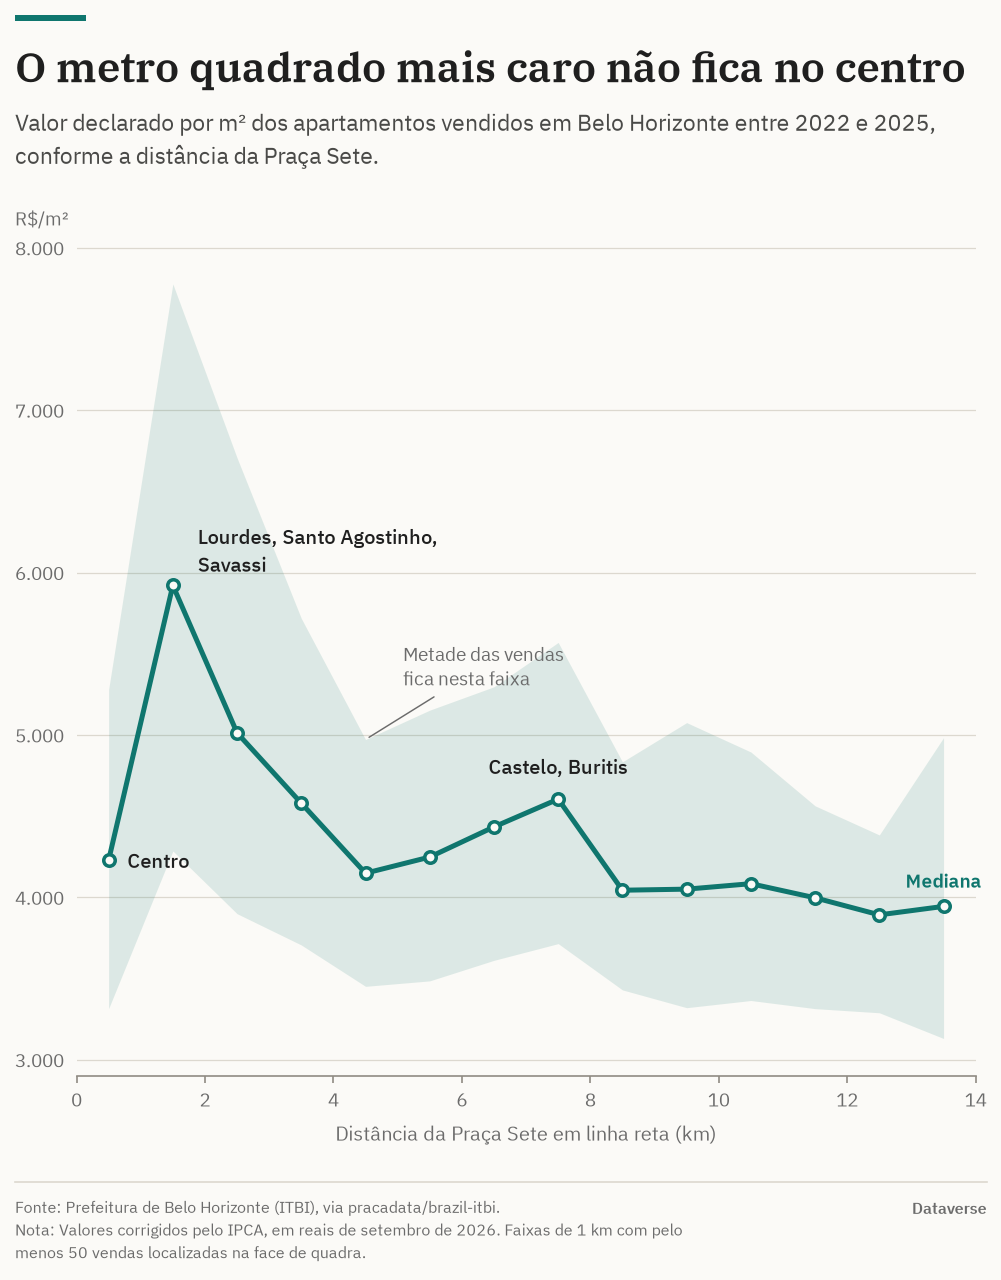

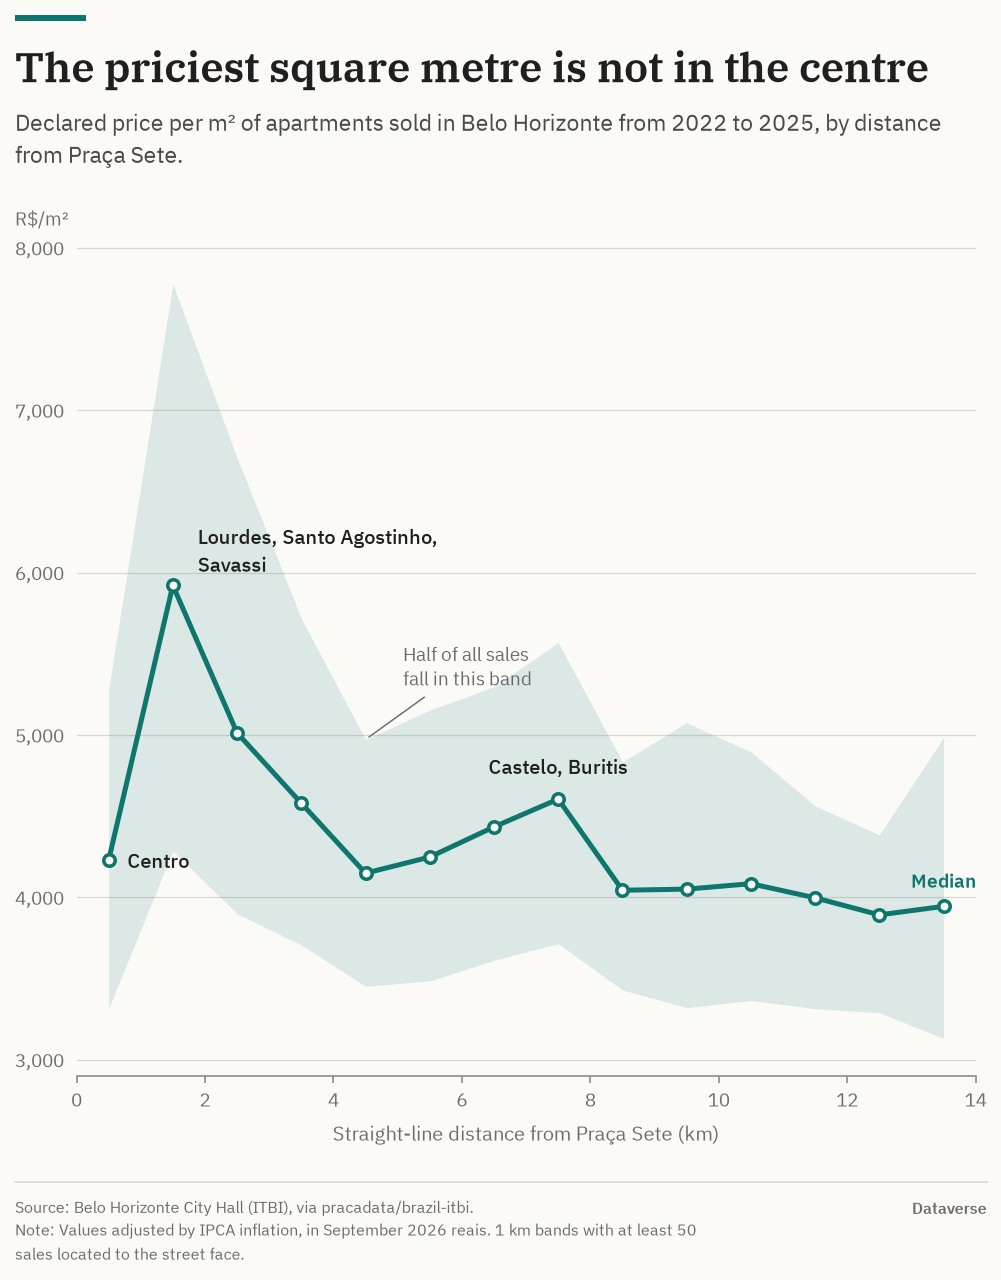

In [11]:
# The first band and the band with the highest median, which get place labels.
first_km, peak_km = gradient.index[0], gradient["median"].idxmax()

GRADIENT_TEXT = {
    "pt": {
        "title": "O metro quadrado mais caro não fica no centro",
        "subtitle": (
            f"Valor declarado por m² dos apartamentos vendidos em Belo Horizonte entre "
            f"{GRADIENT_YEARS[0]} e {GRADIENT_YEARS[1]}, conforme a distância da Praça Sete."
        ),
        "unit": "R$/m²",
        "median": "Mediana",
        "band": "Metade das vendas\nfica nesta faixa",
        "first": "Centro",
        "peak": "Lourdes, Santo Agostinho,\nSavassi",
        "bump": "Castelo, Buritis",
        "xlabel": "Distância da Praça Sete em linha reta (km)",
        "note": (
            "Valores corrigidos pelo IPCA, em reais de setembro de 2026. Faixas de 1 km "
            f"com pelo menos {MIN_SALES_PER_BAND} vendas localizadas na face de quadra."
        ),
    },
    "en": {
        "title": "The priciest square metre is not in the centre",
        "subtitle": (
            f"Declared price per m² of apartments sold in Belo Horizonte from "
            f"{GRADIENT_YEARS[0]} to {GRADIENT_YEARS[1]}, by distance from Praça Sete."
        ),
        "unit": "R$/m²",
        "median": "Median",
        "band": "Half of all sales\nfall in this band",
        "first": "Centro",
        "peak": "Lourdes, Santo Agostinho,\nSavassi",
        "bump": "Castelo, Buritis",
        "xlabel": "Straight-line distance from Praça Sete (km)",
        "note": (
            "Values adjusted by IPCA inflation, in September 2026 reais. 1 km bands "
            f"with at least {MIN_SALES_PER_BAND} sales located to the street face."
        ),
    },
}
# Shared style of the place labels drawn on the data.
place_label = {
    "textcoords": "offset points",
    "fontsize": 9.5,
    "fontweight": "medium",
    "color": DEFAULT_THEME.ink,
}

for lang in LANGUAGES:
    text = GRADIENT_TEXT[lang]
    fig, ax = editorial_subplots(
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE,
        note=text["note"],
        signature=SIGNATURE,
        lang=lang,
    )

    # The middle half of the sales as a band, the median as a line on top of it.
    plot_band(ax, gradient.index, gradient["p25"], gradient["p75"])
    plot_line(ax, gradient.index, gradient["median"])

    # Places, labelled directly on the data instead of in a legend.
    ax.annotate(
        text["peak"],
        (peak_km, gradient.loc[peak_km, "median"]),
        xytext=(12, 4),
        va="bottom",
        linespacing=1.3,
        **place_label,
    )
    ax.annotate(
        text["first"],
        (first_km, gradient.loc[first_km, "median"]),
        xytext=(9, -1),
        va="center",
        **place_label,
    )
    ax.annotate(
        text["bump"],
        (7.5, gradient.loc[7.5, "median"]),
        xytext=(0, 10),
        ha="center",
        va="bottom",
        **place_label,
    )

    # What the line and the band are: accent for the series, grey for the explanation.
    ax.annotate(
        text["median"],
        (gradient.index[-1], gradient["median"].iloc[-1]),
        xytext=(0, 9),
        textcoords="offset points",
        fontsize=9,
        fontweight="semibold",
        color=DEFAULT_THEME.accent,
        ha="center",
    )
    ax.annotate(
        text["band"],
        (4.5, gradient.loc[4.5, "p75"]),
        xytext=(18, 26),
        textcoords="offset points",
        fontsize=9,
        color=DEFAULT_THEME.muted,
        linespacing=1.3,
        arrowprops={
            "arrowstyle": "-",
            "color": DEFAULT_THEME.muted,
            "linewidth": 0.7,
            "shrinkB": 2,
        },
    )

    # The axis starts at about R$ 3,000, not zero, so the baseline stays light.
    style_axes(ax, text["unit"], xlabel=text["xlabel"])
    ax.set_xlim(0, MAX_DISTANCE_KM)
    ax.set_xticks(range(0, MAX_DISTANCE_KM + 1, 2))
    ax.yaxis.set_major_formatter(number_formatter(lang))

    save_figure(fig, OUTPUT_DIR / f"02_distance_gradient_{lang}.png", show=True)

## 5. How did recorded values change after adjustment?

The raw median reflects both the values and the mix of properties sold in a given year. A hedonic regression estimates changes in recorded values after adjusting for the property characteristics in the model:

$$\log p_i = \alpha + \beta \log a_i + \gamma_{\text{age}(i)} + \delta_{\text{type}(i)} + \mu_{\text{neighbourhood}(i)} + \tau_{\text{year}(i)} + \varepsilon_i$$

where $p_i$ is the inflation-adjusted declared value or ITBI tax base per m² of sale $i$ and $a_i$ its built area. The year effects $\tau_t$ are log differences from 2016 for properties of the same size, age band, type and neighbourhood, so $100\,e^{\tau_t}$ is a characteristics-adjusted index with 2016 = 100. Standard errors are clustered by neighbourhood, and only neighbourhoods with at least 100 sales are kept, so each neighbourhood effect rests on enough data.

The model is fitted twice, on two measures of value. The **declared value** is what the parties reported. The **tax base** is the value used to calculate ITBI. The two series can move differently as the relationship between the recorded values changes over time (section 3.2).

In [12]:
# Sales with a known building age, in neighbourhoods with enough sales to
# estimate a neighbourhood effect.
hedonic_data = residential.dropna(subset=["building_age_band"]).copy()
hedonic_data = hedonic_data.loc[
    hedonic_data.groupby("neighbourhood")["neighbourhood"].transform("size")
    >= MIN_SALES_PER_NEIGHBOURHOOD
]

# The dataset deflates only the declared value, so the same monthly IPCA factor
# is recovered from it and applied to the tax base.
deflator = hedonic_data["value_declared_brl_real"] / hedonic_data["value_declared_brl"]
hedonic_data["declared_m2_real"] = hedonic_data["price_per_m2_brl_real"]
hedonic_data["tax_base_m2_real"] = (
    hedonic_data["value_tax_base_brl"] * deflator / hedonic_data["built_area_m2"]
)
# Integer code per neighbourhood, used to cluster the standard errors.
neighbourhood_codes = hedonic_data["neighbourhood"].astype("category").cat.codes

# Fit the same model on each value measure and turn its year effects into an index.
hedonic_models = {}
index_parts = []
for measure, column in MEASURES.items():
    model = smf.ols(FORMULA.format(value=column), data=hedonic_data).fit(
        cov_type="cluster", cov_kwds={"groups": neighbourhood_codes}
    )
    hedonic_models[measure] = model

    # Year coefficients are log differences from 2016; exp() turns them into an index.
    year_terms = model.params.filter(like="C(year)").index
    estimates = pd.concat([model.params[year_terms], model.conf_int().loc[year_terms]], axis=1)
    part = (100 * np.exp(estimates)).set_axis(["hedonic", "lower", "upper"], axis=1)
    part.index = year_terms.str.extract(r"(\d{4})")[0].astype(int)
    part.loc[START_YEAR] = 100.0

    # The raw median of the same sales, on the same 2016 = 100 scale, for comparison.
    raw_median = hedonic_data.groupby("year")[column].median()
    part["raw_median"] = 100 * raw_median / raw_median[START_YEAR]
    index_parts.append(part.sort_index().assign(measure=measure))

    print(
        f"{measure}: {int(model.nobs):,} sales, "
        f"{hedonic_data['neighbourhood'].nunique()} neighbourhoods, R² = {model.rsquared:.3f}"
    )

# One long table (measure, year, index values), shown wide for reading.
price_index = pd.concat(index_parts).rename_axis("year").reset_index()
display(
    price_index.pivot(
        index="year", columns="measure", values=["raw_median", "hedonic"]
    ).style.format("{:.1f}")
)

Declared value: 202,204 sales, 192 neighbourhoods, R² = 0.236


Tax base: 202,204 sales, 192 neighbourhoods, R² = 0.466


The characteristics-adjusted index for declared values reaches 115.4 in 2025 (2016 = 100). The corresponding ITBI tax-base index falls to 87.0 in 2022 and reaches 97.9 in 2025 (95% CI 95.8–100.1). In the model sample, the share of declared values below the tax base falls from about 69% in 2016 to about 24% in 2024. This convergence helps explain why the two measures tell different stories.

In 2025 the raw medians, also indexed to 2016, are 98.1 for declared values and 90.6 for the tax base. The share of new buildings in the model sample falls from 36% in 2016 to 20% in 2025, and the share aged 26 years or more rises from 22% to 37%. That shift could account for part of the gap between the adjusted indices and the raw medians. The model adjusts for area, age band, property type and neighbourhood jointly. Estimating the separate contribution of age would require a decomposition.

The figure uses the recorded ITBI tax base. Changes in assessment or reporting practice may also affect the series.

In [13]:
# Share of each building-age band among the year's sales.
composition = pd.crosstab(
    hedonic_data["year"], hedonic_data["building_age_band"], normalize="index"
)[["new", "3_10", "11_25", "26_plus"]]
# Share of the year's sales declared below the tax base (R$ 1 tolerance).
composition["declared below tax base"] = (
    (hedonic_data["value_declared_brl"] < hedonic_data["value_tax_base_brl"] - 1)
    .groupby(hedonic_data["year"])
    .mean()
)
display(composition.style.format("{:.1%}"))

building_age_band,new,3_10,11_25,26_plus,declared below tax base
year,,,,,
2016,36.0%,21.8%,20.6%,21.6%,68.9%
2017,30.9%,24.0%,22.1%,23.1%,72.6%
2018,28.2%,26.3%,21.9%,23.6%,69.5%
2019,21.8%,30.9%,22.9%,24.4%,66.4%
2020,21.0%,29.4%,24.3%,25.3%,54.4%
2021,21.5%,27.0%,25.8%,25.8%,45.5%
2022,21.3%,22.6%,26.0%,30.1%,35.2%
2023,20.6%,20.9%,26.7%,31.8%,27.0%
2024,20.8%,17.3%,28.0%,33.9%,24.3%


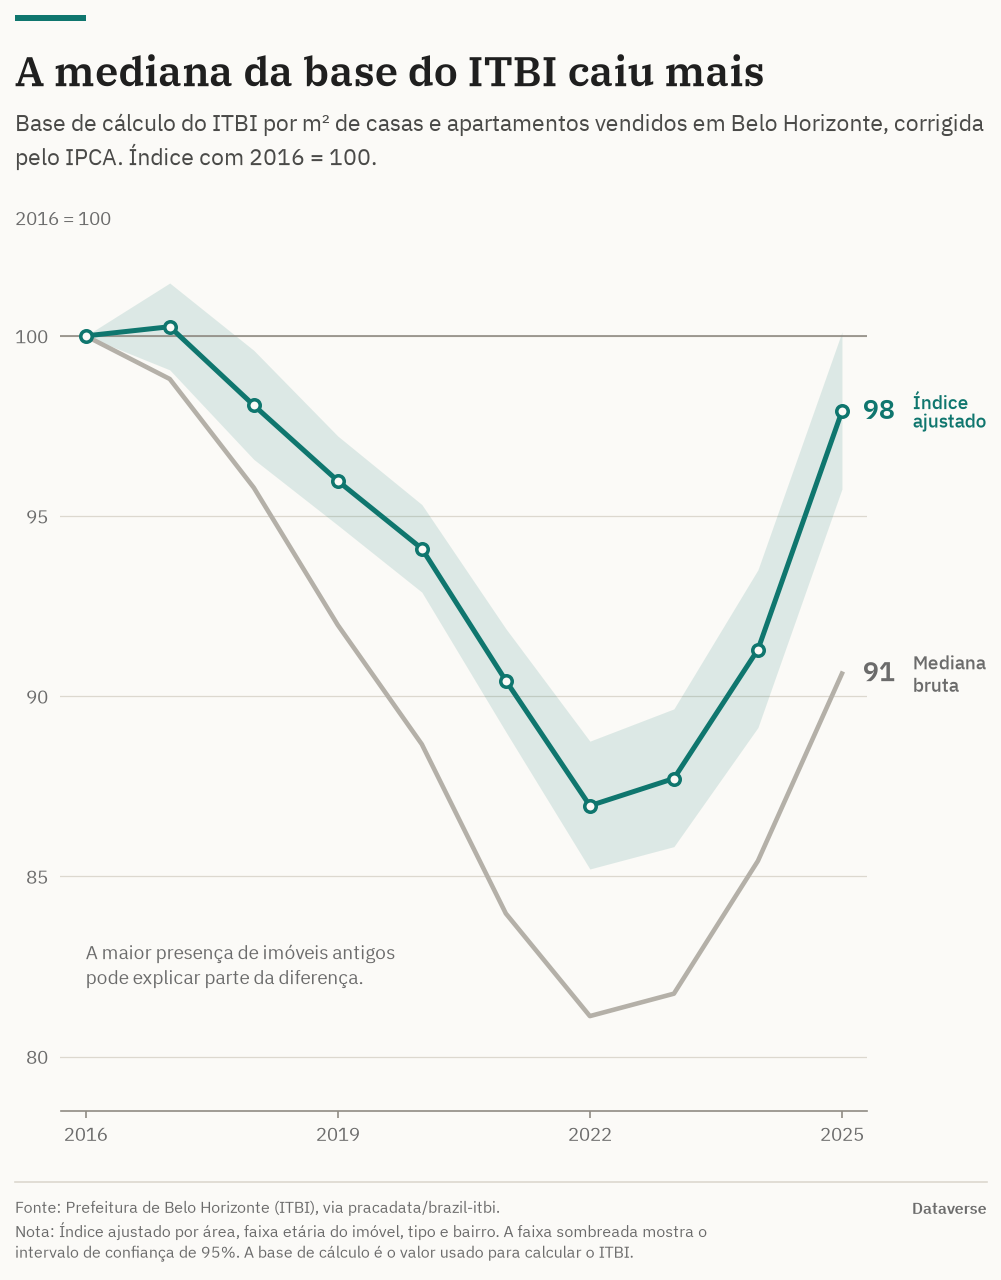

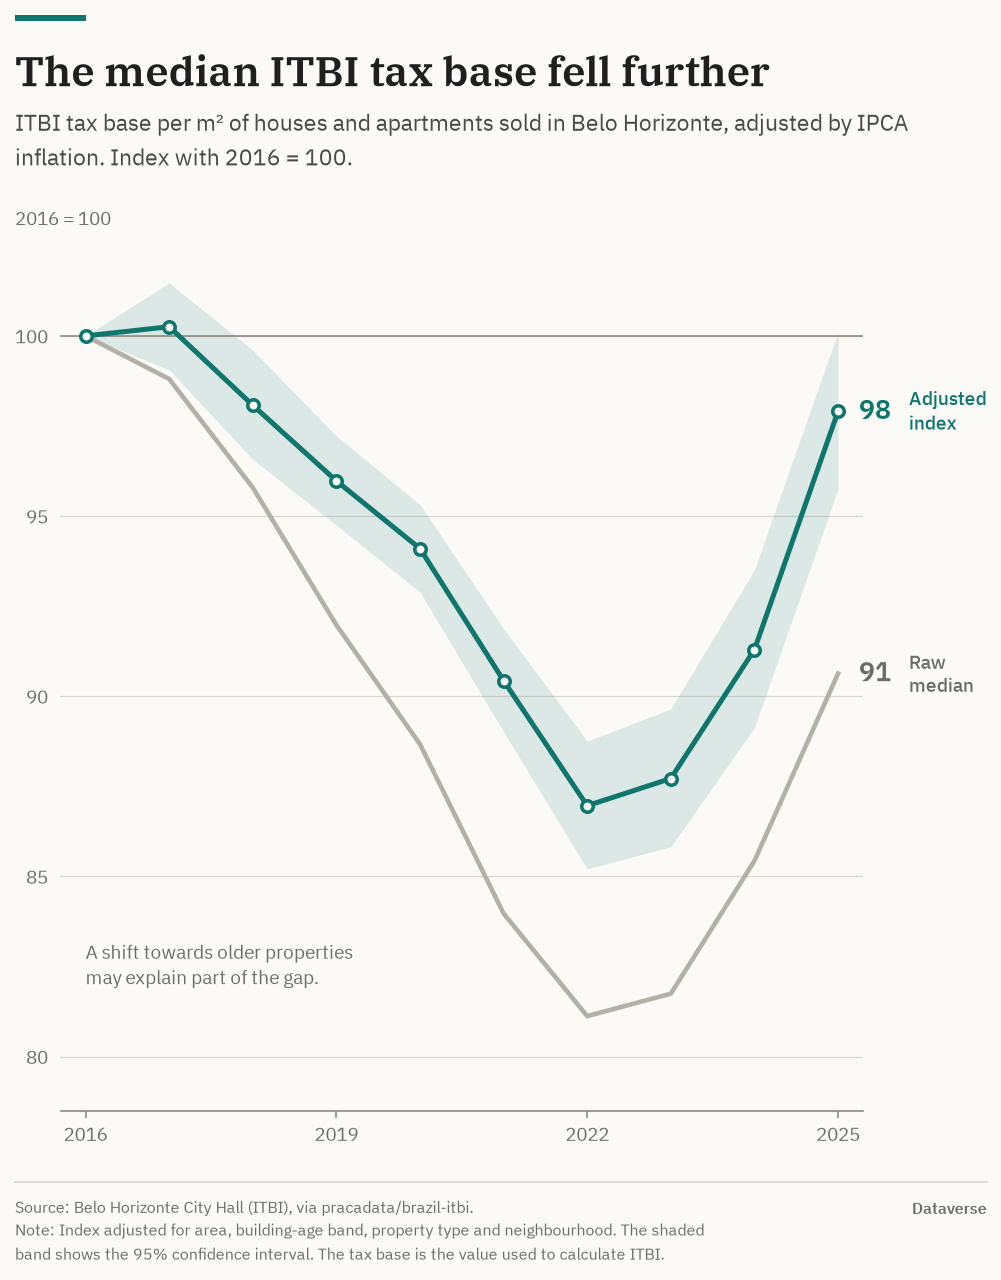

In [14]:
# The post figure uses the tax base; its title describes that result, so the
# texts below need rewriting if the measure is ever changed.
index = price_index.loc[price_index["measure"] == "Tax base"].set_index("year")
last = index.loc[END_YEAR]

INDEX_TEXT = {
    "pt": {
        "title": "A mediana da base do ITBI caiu mais",
        "subtitle": (
            "Base de cálculo do ITBI por m² de casas e apartamentos vendidos em "
            f"Belo Horizonte, corrigida pelo IPCA. Índice com {START_YEAR} = 100."
        ),
        "unit": f"{START_YEAR} = 100",
        "hedonic": "Índice\najustado",
        "raw": "Mediana\nbruta",
        "gap": "A maior presença de imóveis antigos\npode explicar parte da diferença.",
        "note": (
            "Índice ajustado por área, faixa etária do imóvel, tipo e bairro. A faixa sombreada "
            "mostra o intervalo de confiança de 95%. A base de cálculo é o valor usado "
            "para calcular o ITBI."
        ),
    },
    "en": {
        "title": "The median ITBI tax base fell further",
        "subtitle": (
            "ITBI tax base per m² of houses and apartments sold in Belo Horizonte, "
            f"adjusted by IPCA inflation. Index with {START_YEAR} = 100."
        ),
        "unit": f"{START_YEAR} = 100",
        "hedonic": "Adjusted\nindex",
        "raw": "Raw\nmedian",
        "gap": "A shift towards older properties\nmay explain part of the gap.",
        "note": (
            "Index adjusted for area, building-age band, property type and neighbourhood. "
            "The shaded band shows the 95% confidence interval. The tax base is the value "
            "used to calculate ITBI."
        ),
    },
}

for lang in LANGUAGES:
    text = INDEX_TEXT[lang]
    fig, ax = editorial_subplots(
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE,
        note=text["note"],
        signature=SIGNATURE,
        lang=lang,
    )

    # The 2016 level, slightly darker than the grid, as the line of reference.
    ax.axhline(100, color=DEFAULT_THEME.axis, linewidth=0.8)

    # Raw median in grey (context); quality-constant index in the accent colour,
    # with its confidence band.
    plot_line(
        ax,
        index.index,
        index["raw_median"],
        color=DEFAULT_THEME.context,
        markers=False,
        linewidth=2.2,
    )
    plot_band(ax, index.index, index["lower"], index["upper"])
    plot_line(ax, index.index, index["hedonic"])

    # Each line is named at its right end, with its final value.
    for column, label, colour in [
        ("hedonic", text["hedonic"], DEFAULT_THEME.accent),
        ("raw_median", text["raw"], DEFAULT_THEME.muted),
    ]:
        ax.annotate(
            f"{last[column]:.0f}",
            (END_YEAR, last[column]),
            xytext=(10, 0),
            textcoords="offset points",
            va="center",
            fontsize=13,
            fontweight="semibold",
            color=colour,
        )
        ax.annotate(
            label,
            (END_YEAR, last[column]),
            xytext=(34, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
            fontweight="medium",
            color=colour,
            linespacing=1.2,
        )

    # Note a plausible contributor to the difference between the two series.
    ax.annotate(
        text["gap"],
        (START_YEAR, 82.5),
        xytext=(0, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=DEFAULT_THEME.muted,
        linespacing=1.35,
    )

    # The axis does not start at zero, so the baseline stays light.
    style_axes(ax, text["unit"])
    ax.set_xticks(range(START_YEAR, END_YEAR + 1, 3))
    ax.set_xlim(START_YEAR - 0.3, END_YEAR + 0.3)
    ax.set_yticks(range(80, 101, 5))
    ax.set_ylim(78.5, 102.5)

    save_figure(fig, OUTPUT_DIR / f"03_price_index_{lang}.png", show=True)

## 6. Clustering at round declared values

For 2023–2025, the analysis groups nominal declared values from R$55,000 to under R$1,045,000 into R$10,000 bins. A round bin is centred on an exact multiple of R$50,000. The share of declarations at those exact values and the share within the round bins are both observed directly.

To estimate excess clustering, a Poisson regression with a natural cubic spline is fitted to the non-round bins. Its predictions are then rescaled to the total observed count across all bins. The lower panel measures the percentage by which each round bin exceeds this fitted reference.

With seven spline degrees of freedom, the round bins contain 30.50% of sales against a fitted share of 19.84%. Using five or nine degrees of freedom gives fitted shares of 19.76% and 19.86%, respectively. The aggregate excess is similar across these fits, while estimates for individual bins vary with the smooth curve.

In [15]:
BUNCH_YEARS = (2023, 2025)
BUNCH_BIN = 10_000  # bin width, in reais
ROUND_STEP = 50_000  # a bin is round when its centre is a multiple of this
BUNCH_RANGE = (
    55_000,
    1_045_000,
)  # from, up to but excluding: bins centred on R$ 60 mil to R$ 1.04 million
SPLINE_DF = 7  # flexibility of the smooth expected curve

# Recent sales with a declared value inside the range covered by the bins.
bunch_sales = residential.loc[
    residential["year"].between(*BUNCH_YEARS)
    & residential["value_declared_brl"].between(*BUNCH_RANGE, inclusive="left")
]
values = bunch_sales["value_declared_brl"]

# Count the sales in bins centred on multiples of BUNCH_BIN. floor(x + 0.5)
# sends every half-way value to the bin above it; round() would send it to the
# nearest even bin and favour some bins over others.
bunching = (
    (np.floor(values / BUNCH_BIN + 0.5) * BUNCH_BIN)
    .astype(int)
    .value_counts()
    .sort_index()
    .rename_axis("value")
    .reset_index(name="observed")
)
bunching["is_round"] = bunching["value"] % ROUND_STEP == 0

# Expected counts: a smooth curve fitted only to the bins that are not round,
# then rescaled so that expected and observed totals match. The uncentred
# spline basis already spans the constant, so omit the separate intercept.
smooth_model = smf.glm(
    f"observed ~ 0 + cr(value, df={SPLINE_DF})",
    data=bunching.loc[~bunching["is_round"]],
    family=sm.families.Poisson(),
).fit()
bunching["expected"] = smooth_model.predict(bunching)
bunching["expected"] *= bunching["observed"].sum() / bunching["expected"].sum()
bunching["excess"] = bunching["observed"] / bunching["expected"] - 1
round_bins = bunching.loc[bunching["is_round"]]

# Three summaries: exact round values, and round bins observed against expected.
exact_share = (values % ROUND_STEP == 0).mean()
observed_share = round_bins["observed"].sum() / bunching["observed"].sum()
expected_share = round_bins["expected"].sum() / bunching["expected"].sum()

print(f"{len(values):,} sales in {len(bunching)} bins, {len(round_bins)} of them round")
print(f"Declared at an exact multiple of R$ {ROUND_STEP:,}: {exact_share:.1%}")
print(f"Share of sales in round bins: {observed_share:.1%} observed, {expected_share:.1%} expected")
display(
    round_bins.set_index("value")
    .drop(columns="is_round")
    .style.format({"observed": "{:,}", "expected": "{:,.0f}", "excess": "{:+.0%}"})
)

58,177 sales in 99 bins, 19 of them round
Declared at an exact multiple of R$ 50,000: 22.1%
Share of sales in round bins: 30.5% observed, 19.8% expected


,observed,expected,excess
value,,,
100000,420,324,+29%
150000,962,696,+38%
200000,"1,487","1,207",+23%
250000,"2,056","1,519",+35%
300000,"1,873","1,422",+32%
350000,"2,074","1,138",+82%
400000,"1,312",898,+46%
450000,"1,075",753,+43%
500000,"1,130",654,+73%


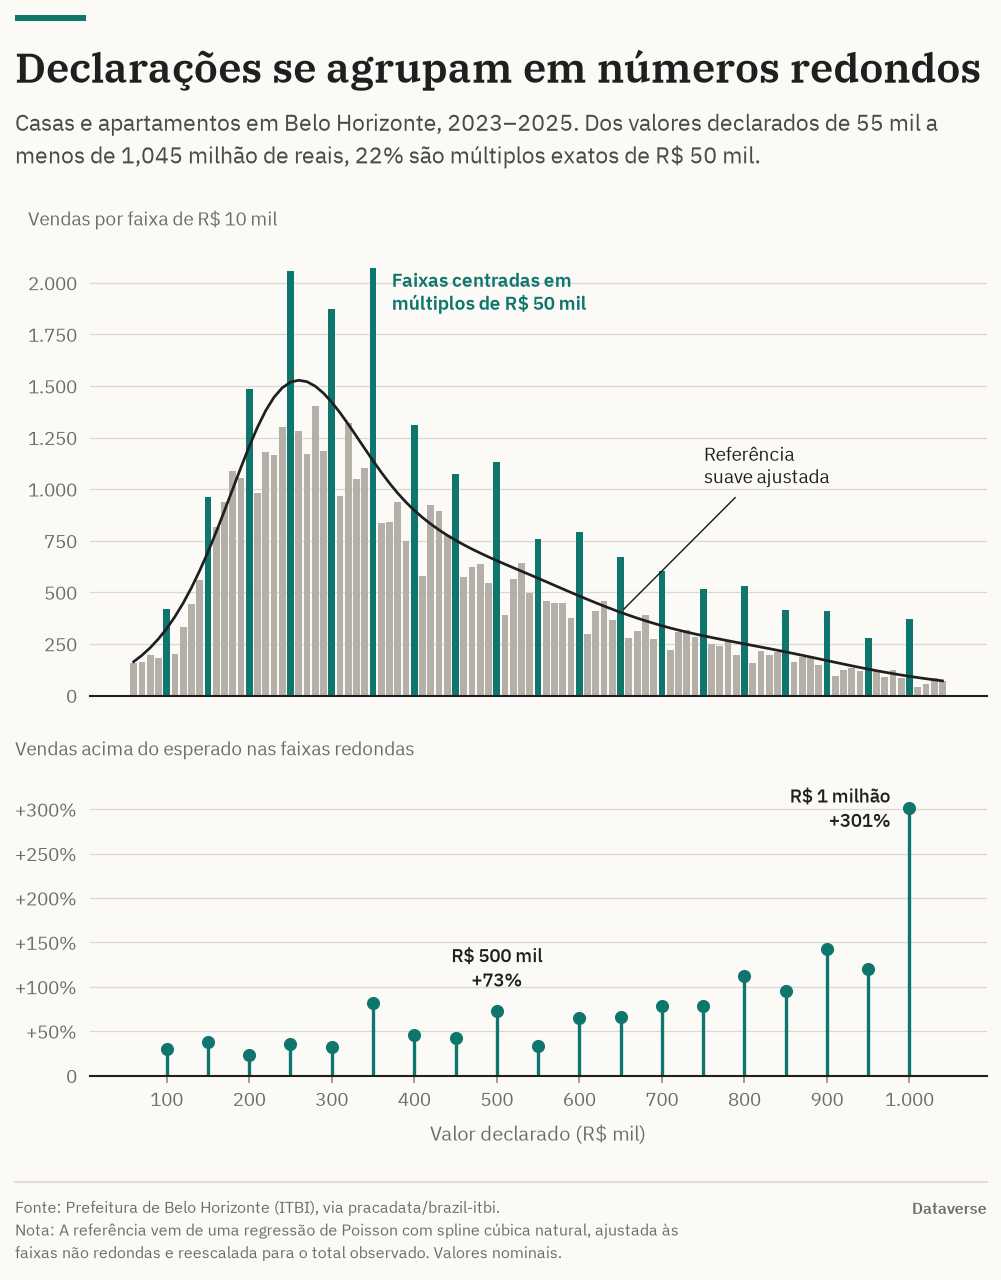

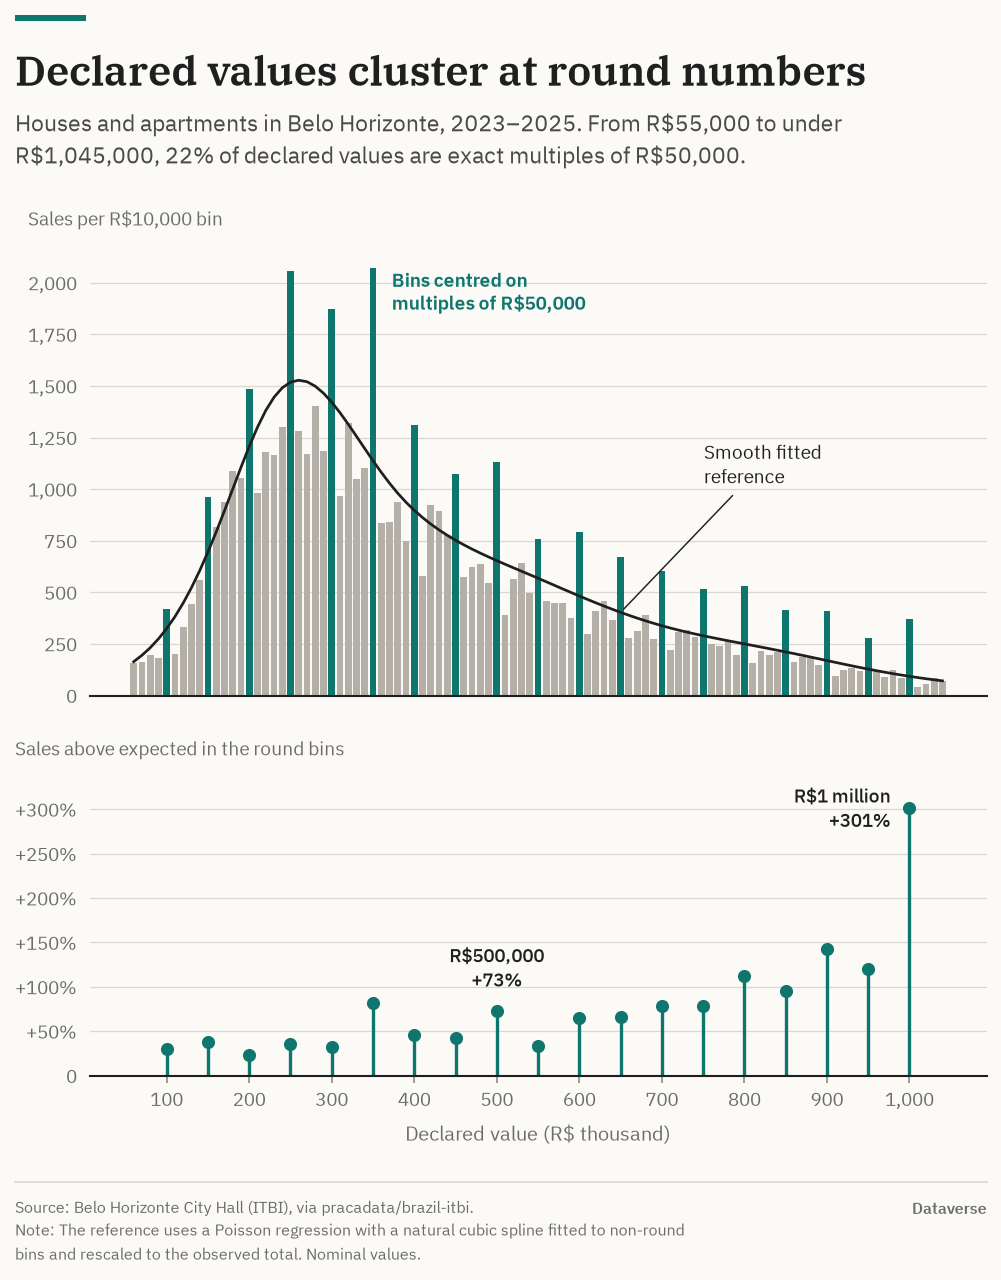

In [16]:
# The two round values that get a label in the lower panel, and where each
# label sits relative to its point (offset in points, alignment).
LABELLED = {
    500_000: {
        "pt": "R$ 500 mil",
        "en": "R$500,000",
        "place": {"xytext": (0, 9), "ha": "center", "va": "bottom"},
    },
    1_000_000: {
        "pt": "R$ 1 milhão",
        "en": "R$1 million",
        "place": {"xytext": (-9, 0), "ha": "right", "va": "center"},
    },
}

BUNCH_TEXT = {
    "pt": {
        "title": "Declarações se agrupam em números redondos",
        "subtitle": (
            f"Casas e apartamentos em Belo Horizonte, {BUNCH_YEARS[0]}–{BUNCH_YEARS[1]}. "
            f"Dos valores declarados de 55 mil a menos de 1,045 milhão de reais, "
            f"{exact_share:.0%} são múltiplos exatos de R$ 50 mil."
        ),
        "unit_top": "Vendas por faixa de R$ 10 mil",
        "unit_bottom": "Vendas acima do esperado nas faixas redondas",
        "round": "Faixas centradas em\nmúltiplos de R$ 50 mil",
        "expected": "Referência\nsuave ajustada",
        "xlabel": "Valor declarado (R$ mil)",
        "note": (
            "A referência vem de uma regressão de Poisson com spline cúbica natural, ajustada "
            "às faixas não redondas e reescalada para o total observado. Valores nominais."
        ),
    },
    "en": {
        "title": "Declared values cluster at round numbers",
        "subtitle": (
            f"Houses and apartments in Belo Horizonte, {BUNCH_YEARS[0]}–{BUNCH_YEARS[1]}. "
            f"From R$55,000 to under R$1,045,000, {exact_share:.0%} of declared values "
            "are exact multiples of R$50,000."
        ),
        "unit_top": "Sales per R$10,000 bin",
        "unit_bottom": "Sales above expected in the round bins",
        "round": "Bins centred on\nmultiples of R$50,000",
        "expected": "Smooth fitted\nreference",
        "xlabel": "Declared value (R$ thousand)",
        "note": (
            "The reference uses a Poisson regression with a natural cubic spline fitted to non-round "
            "bins and rescaled to the observed total. Nominal values."
        ),
    },
}

# Values are plotted in thousands of reais.
x = bunching["value"] / 1_000
x_round = round_bins["value"] / 1_000

for lang in LANGUAGES:
    text = BUNCH_TEXT[lang]
    # Header and footer first, then two stacked panels sharing the x axis.
    fig, (ax_counts, ax_excess) = editorial_subplots(
        2,
        1,
        sharex=True,
        height_ratios=[3, 2],
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE,
        note=text["note"],
        signature=SIGNATURE,
        lang=lang,
    )

    # Upper panel: observed counts as bars (round bins in the accent colour)
    # and the expected counts as a line.
    ax_counts.bar(
        x,
        bunching["observed"],
        width=BUNCH_BIN / 1_000 * 0.82,
        color=np.where(bunching["is_round"], DEFAULT_THEME.accent, DEFAULT_THEME.context),
    )
    ax_counts.plot(x, bunching["expected"], color=DEFAULT_THEME.ink, linewidth=1.3)
    ax_counts.annotate(
        text["round"],
        (350, bunching.set_index("value").loc[350_000, "observed"]),
        xytext=(9, 0),
        textcoords="offset points",
        fontsize=9,
        fontweight="semibold",
        color=DEFAULT_THEME.accent,
        va="top",
        linespacing=1.3,
    )
    ax_counts.annotate(
        text["expected"],
        (650, bunching.set_index("value").loc[650_000, "expected"]),
        xytext=(40, 62),
        textcoords="offset points",
        fontsize=9,
        color=DEFAULT_THEME.ink,
        linespacing=1.3,
        arrowprops={"arrowstyle": "-", "color": DEFAULT_THEME.ink, "linewidth": 0.7, "shrinkB": 2},
    )

    # Lower panel: how far each round bin sits above its expected count.
    ax_excess.vlines(x_round, 0, round_bins["excess"], color=DEFAULT_THEME.accent, linewidth=1.6)
    ax_excess.scatter(x_round, round_bins["excess"], s=28, color=DEFAULT_THEME.accent, zorder=3)
    for value, names in LABELLED.items():
        excess = round_bins.set_index("value").loc[value, "excess"]
        ax_excess.annotate(
            f"{names[lang]}\n+{excess:.0%}",
            (value / 1_000, excess),
            textcoords="offset points",
            fontsize=9,
            fontweight="medium",
            color=DEFAULT_THEME.ink,
            linespacing=1.3,
            **names["place"],
        )

    # Both panels start at zero, so both get the dark baseline.
    style_axes(ax_counts, text["unit_top"], zero_baseline=True)
    style_axes(ax_excess, text["unit_bottom"], zero_baseline=True, xlabel=text["xlabel"])
    ax_counts.tick_params(axis="x", labelbottom=False, length=0)
    ax_counts.yaxis.set_major_formatter(number_formatter(lang))
    ax_excess.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"+{v:.0%}" if v else "0"))
    ax_excess.set_ylim(0, round_bins["excess"].max() * 1.12)
    ax_excess.set_xticks(range(100, 1_001, 100))
    ax_excess.xaxis.set_major_formatter(number_formatter(lang))

    save_figure(fig, OUTPUT_DIR / f"04_round_numbers_{lang}.png", show=True)